## Pegasus Evaluation: Iterative Optimization

Section C of the evaluation of the paper. The evaluation is split into `2a_base_case.ipynb` (A, B.1), `2b_evidence.ipynb` (B.2, B.2b), `2c_depth_and_load.ipynb` (B.3, B.4), `2d_tails_and_percentiles.ipynb` (B.5, B.6) and `2e_iterative.ipynb` (C.1, C.2). `2a_base_case.ipynb` describes
the two data sources, the setup (A) and the metrics and methods (B.1) that every notebook uses; the parameters are
defined once in `pegasus/evaluation_setup.py`. C.2 is not supported by the real data yet and runs on synthetic data
when `data_source` is "real" (C.2 says why). Choose the data source with `data_source` in the first code cell.

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
from pegasus.figures import math_label
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/evaluation_cache/ (written by the first
# notebook that needs it), or computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 loaded from statics/evaluation_cache/b1_real+b1+b1u-max3_0e04951dbc7be6a8.joblib
real data, 3 seeds: chain detector -> transformer -> compressor, per seed 25 training configurations per service and 120 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 65/s)


## C. Iterative Optimization of Service Bounds

**Note (speed of the bounds).** The experiments of this section compute the bound of Pegasus again and again: for every
candidate configuration or composition that an optimizer grades, and after every update with end-to-end samples. Pegasus
per node evaluates one closed formula per service, and Pegasus SNC minimizes once over a fixed grid of θ. B.2 reports the evaluation time of Pegasus Node against the amount of training data, and B.3
that of both versions against the depth of the application.

### C.1 Fine-Tuning Bounds with E2E Samples

- **Synthetic:** the chain of B.1, with a part of its held-out configurations as end-to-end samples.
- **Real:** the base chain of B.1 (`base_experiment`: object detector → image transformer → image compressor), with a
  part of its held-out runs as end-to-end samples. Its held-out runs are those of B.1 (`2a_base_case.ipynb`, Services
  and Chains: the runs with one worker per service and the runs with at most three), enough for both the end-to-end
  samples and a test set (calibrating at the level `confidence` alone needs at least 19 samples, see Fine-tuning
  below). An end-to-end sample is a measured run of the chain, at the arrival rate that the campaign set for it; the
  samples are drawn from all held-out runs, so they mix runs with one and with several workers per service, as the
  test set does.
- **Baselines:** the only experiment with models trained on runs of the chain, because using end-to-end samples is
  its subject: Quantile Sum and the Fluxion-style composition, with a growing number of samples. Deep GP Advanced is
  left out: it needs minutes of training per number of samples and seed (`1_method_synthetic.ipynb`, Section 7d, shows
  it on the synthetic system). Of the proposed method, only Pegasus Node is fine-tuned: Pegasus SNC is evaluated in B.1 and B.3 only.

**Question.** A bound of B is computed before the chain is ever run. Once the chain runs, every run gives one
*end-to-end sample*: a configuration of the chain together with its measured $(1-\varepsilon)$ latency quantile. How
many samples does it take to tighten the bound, and does it stay valid?

**Setting.** For every seed, the chain, the models and the results of B.1; nothing of B is computed again. The
held-out configurations of B.1 are split at random: `c1_sizes[-1]` of them can serve as end-to-end samples, and the
rest is the test set, which is the same for every number of samples. A setting uses the first $n$ samples, one value
of `c1_sizes` per setting; $n = 0$ is the bound of B.1 on the test set.

**Fine-tuning (`pegasus/finetuning.py`).** The bound is multiplied by one factor that is calibrated on the samples
(split-conformal calibration). The *score* of a sample is its measured quantile ÷ the bound at its configuration:
below 1 where the bound has room, above 1 where the bound is violated. The factor is the
$\lceil (n+1)\,\gamma \rceil$-th smallest score, with $\gamma$ = `confidence`. It lies below 1 if the bound was looser than the
samples require, and the bound becomes tighter; it lies above 1 if the samples violate the bound, and the bound is
raised. If the samples and the configuration that the bound is used at are exchangeable (drawn in the same way), the
fine-tuned bound lies above the measured quantile of that configuration with probability at least $\gamma$. That is a
different guarantee than the one of B: it holds on average over the configurations and the samples, it only holds for
the chain and the workload that the samples were taken from, and it replaces the assumptions of the bound by the
assumption of exchangeability. The rank $\lceil (n+1)\,\gamma \rceil$ must not exceed $n$, so the level $\gamma$ needs a
minimum number of samples; with fewer, the bound stays as it is and keeps the guarantee of B. An infinite bound stays
infinite. The factor is one number for all configurations, so it can only tighten the bound as far as the samples at
which the bound has the least room allow: where the room of the bound differs between groups of runs (for example
between runs with one and with several workers per service), those with the least room set the factor.

**Baselines trained on the samples.**
- *Quantile Sum:* one GP per service predicts the $(1-\varepsilon)$ latency quantile that the service had inside the
  chain, from the configuration of the service (with real data also from the arrival rate of the run, which differs
  between runs); the predictions are added. It is not a baseline of B, because it needs
  runs of the chain.
- *Fluxion-style:* one GP per position of the chain and quantile level, which receives the configuration of the chain
  and the predicted quantiles of the position before it (`pegasus/baselines_chain.py`, part 4).

Neither is a guarantee: both are point predictions of the quantile. With $n = 0$ they cannot be trained.

**Figure** (also saved as `figures/tsc/c1_finetuning_<data source>.pdf` and `.jpg`). The horizontal axis is the
number of end-to-end samples $n$, the vertical axis the tightness on the test set, for every seed the median over its
test configurations of latency ÷ measured quantile. Unlike the figures of B, which share the logarithmic range of 0.2× to 64×, the vertical axis is linear and
zoomed to the values of C.1, so that their differences are visible. The black line at 1× is the measured quantile;
in the red area below it ("underestimated: SLO violated") a method lies under the measured quantile, so a
configuration chosen with it to meet a latency SLO would violate the SLO. Pegasus Node starts at $n = 0$ from the bound of B.1, where the pretraining on
the services left it, and from there on show the bound fine-tuned with the first $n$ samples; Quantile Sum and
Fluxion-style start at the smallest $n$, because they cannot be trained without samples. Every line is the median over
the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker means that the method
holds at that $n$ (it reaches the confidence level on the test set under every seed, as defined in B.1), a hollow marker
that it does not. The test set is smaller than the held-out set of B.1, so one missed configuration weighs more in the
coverage. Look at where the line of Pegasus Node falls below its start, and whether its markers stay filled.

In [2]:
if "C.1" in skipped:
    print("C.1 skipped: not supported by the {} data".format(data_source))
else:
    # C.1: the results of B.1 with a part of the held-out configurations as end-to-end samples. This cell imports what it needs
    # itself, so that nothing above has to be run again.
    from pegasus.finetuning import COLORS as C1_COLORS, finetuning_figure, finetuning_methods, split_samples

    METHOD_COLORS.update(C1_COLORS)   # colors of the two baselines of C.1
    # number of end-to-end samples; 0 is the bound of B.1 on the test set. Real data: up to 50 of the held-out runs of the base chain, which
    # leaves about half of them as the test set and makes the calibrated coverage more reliable (prototype_run_budget.py)
    c1_sizes = [0, 5, 10, 20, 25] if data_source == "synthetic" else [0, 5, 10, 20, 30, 40, 50]

    def compute():
        c1_methods, c1_truth = {}, {}   # (size, seed) -> name -> (group, latency per test configuration) / (measured quantile, its lower edge)
        with warnings.catch_warnings():
            # the GPs of the two baselines are fitted on few samples, and scikit-learn warns where their hyperparameters end at their bounds
            warnings.simplefilter("ignore", ConvergenceWarning)
            for s, (seed_methods, _) in zip(seeds, per_seed):
                samples, test = split_samples(len(bases[s].measured), c1_sizes[-1], np.random.default_rng([seed, s, 100]))
                for size in c1_sizes:
                    # finetuning_methods fine-tunes both versions of Pegasus; C.1 keeps Pegasus Node only
                    c1_methods[(size, s)] = {name: result for name, result in finetuning_methods(
                        bases[s], seed_methods, samples[:size], test, alpha, miscoverage=1 - confidence).items() if name != PROPOSED_SNC}
                    c1_truth[(size, s)] = (bases[s].measured[test], bases[s].measured_low[test])
        return dict(c1_methods=c1_methods, c1_truth=c1_truth, n_c1_test=len(test))

    globals().update(cached("c1_finetuning", data_source, compute, inputs=dict(c1_sizes=c1_sizes)))
    print(f"{len(c1_methods)} combinations of sample size and seed evaluated, {n_c1_test} test configurations per seed.")

c1_finetuning: results loaded from statics/evaluation_cache/c1_finetuning_real+b1+b1u-max3_ab2d46aea4738be7.joblib
21 combinations of sample size and seed evaluated, 70 test configurations per seed.


legend_inside: the legend hides 4 points or bands at its best location (upper right)


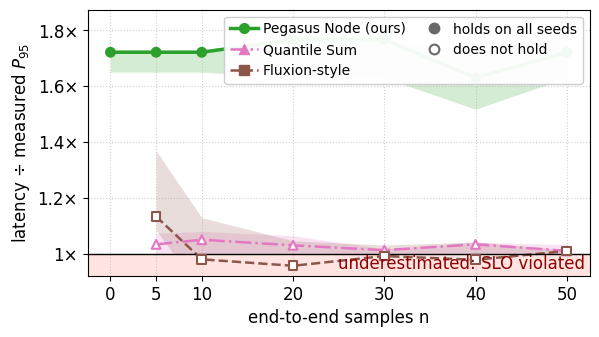

In [3]:
if "C.1" in skipped:
    print("C.1 skipped: not supported by the {} data".format(data_source))
else:
    # source: c1_methods and c1_truth of the cell above (the results of B.1 with end-to-end samples); style of problem_figure.py
    c1_statistics = sweep_statistics(c1_methods, c1_truth, c1_sizes, seeds, confidence)   # name -> coverage, tightness, holds, computed
    finetuning_figure(c1_sizes, c1_statistics, p_label, output=Path("../../figures/tsc") / f"c1_finetuning_{data_source}")

In [4]:
if "C.1" in skipped:
    print("C.1 skipped: not supported by the {} data".format(data_source))
else:
    c1_label = lambda size: f"n = {size}"
    c1_names = [PROPOSED] + list(C1_COLORS)
    median_tightness = lambda name, size: np.nanmedian(c1_statistics[name]["tightness"][c1_sizes.index(size)])   # median over the seeds
    # sample sizes at which the fine-tuned bound differs from the bound of B.1 (n = 0)
    enough = [size for size in c1_sizes[1:] if not np.allclose(c1_statistics[PROPOSED]["tightness"][c1_sizes.index(size)],
                                                               c1_statistics[PROPOSED]["tightness"][0], equal_nan=True)]
    display(Markdown(
        f"**What this shows** ({data_source} data, {arrivals}, ε = {alpha:g}, {len(seeds)} seeds, {n_c1_test} test configurations per seed).\n"
        + sweep_conclusion(c1_sizes, c1_statistics, c1_names, c1_label)
        + "\n- **When fine-tuning starts to act.** "
        + (f"The bound of Pegasus differs from the bound of B.1 from {c1_label(enough[0])} on; with fewer samples the level "
           f"{confidence:.0%} cannot be calibrated, and the bound stays as it is. " if enough else
           "With none of these numbers of samples can the level be calibrated, so the bound stays as it is. ")
        + f"From {c1_label(0)} to {c1_label(c1_sizes[-1])}: "
        + "; ".join(f"{name} from {median_tightness(name, 0):.2f}× to {median_tightness(name, c1_sizes[-1]):.2f}×" for name in [PROPOSED])
        + " (median over the seeds)."
    ))

**What this shows** (real data, poisson arrivals at one rate per configuration (1.58 to 65/s), ε = 0.05, 3 seeds, 70 test configurations per seed).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus Node (ours). Methods that do not hold, and where: Quantile Sum at every setting; Fluxion-style at every setting. Quantile Sum is not computed at n = 0. Fluxion-style is not computed at n = 0.
- **Tightness among the methods that hold** (median over the seeds): Pegasus Node (ours) from 1.72× at n = 0 to 1.72× at n = 50.
- **When fine-tuning starts to act.** The bound of Pegasus differs from the bound of B.1 from n = 20 on; with fewer samples the level 95% cannot be calibrated, and the bound stays as it is. From n = 0 to n = 50: Pegasus Node (ours) from 1.72× to 1.72× (median over the seeds).

### C.2 Inferring Faster Service Compositions

> **TODO: reformulate C.2.** The objective below maximizes a weighted SLO fulfillment over quality and latency. What
> the experiment should answer instead: what is the *minimum budget of resources* (the cost of a configuration) at
> which the chain reaches the target latency with the target accuracy? Latency and accuracy then become constraints
> that a configuration must meet, and the cost is what the optimizer minimizes. The optimizers, the choice among the
> existing runs and the refitting of the models after every evaluated run can stay; the objective, the metrics and the
> conclusions below have to change.

- **Synthetic:** the chain of B.1; the existing runs are its held-out configurations.
- **Real:** not supported: the optimization needs every run at one common arrival rate (below), but the second
  campaign measured every run at its own rate. With `data_source = "real"`, C.2 therefore runs on synthetic data, on the
  synthetic base case of B.1 (`c2_source` in the code cell), while C.1 keeps the real data.
- **Methods:** Pegasus Node and the baselines of B.2 to B.6, each under the same two optimizers.
  Reference: random search.

**Question.** A latency model is useful if an optimizer that relies on it finds a good configuration with few runs of
the chain. Which method leads the optimizer to the best configuration, and how fast?

**Objective: SLO fulfillment.** As in the multidimensional scaling paper (Sedlak et al., IEEE TSC), a *service level
objective* (SLO) relates a metric $m$ to a target $t$, and its *fulfillment* $\phi$ is a number between 0 and 1 that
cannot exceed 1: an SLO cannot be overfulfilled.
- *Quality SLOs* (a larger metric is better): $\phi = \min(1, m / t)$. With real data they are the resolution of the
  QR-code detector and of the object detector and the model size of the object detector and of the face detector; with
  synthetic data the quality knob of the configuration. The targets are in the code cell (`quality_slos`).
- *Latency SLO* (a smaller metric is better): $\phi = \min(1, t / m)$, with $m$ the $(1-\varepsilon)$ quantile of the
  end-to-end latency (s) and $t$ = `latency_target`. The target is the median of the measured quantiles of the existing
  runs, so that about half of them meet it. A configuration without a finite latency has $\phi = 0$.

The objective of a configuration is the weighted mean of the fulfillments: the latency SLO has the weight
`latency_weight`, and the quality SLOs share the rest equally. A higher quality makes a service slower, so the two
kinds of SLO pull in opposite directions. The *predicted* objective uses the latency that a method gives for the
configuration; the *true* objective uses the measured quantile.

**One arrival rate for all runs.** An optimizer chooses a configuration for a given workload, so every run has the
same arrival rate here (synthetic data: the one of B.1; real data: `c2_rate`, unlike B, where every real run has its
own rate). A real run whose busiest service is overloaded at that rate has no latency quantile, and its latency SLO is
not fulfilled at all.

**Optimizers (`pegasus/optimization.py`).** An optimizer *evaluates* one existing run after the other, `c2_budget` in
total, starting from a run drawn at random (the same for every method). Evaluating a run reveals its measured latency
and what the run measured about every service: with real data the mean and the spread of its processing time, with
synthetic data one execution time. These are added to the training data of the method, and its models are fitted anew
before the next choice. The two optimizers differ in how they choose the next run:
- *Best of the runs:* the run with the largest predicted objective among the runs that are not evaluated yet. This is
  the random optimizer of Fluxion (Liang et al., NSDI 2023), which takes the best of many candidate settings according
  to the model; the candidates here are the existing runs.
- *Gradient steps:* the gradient of the predicted objective with respect to the configuration is computed at the run
  evaluated last, from the predictions half a standard deviation up and down in every knob. The next run is the not
  yet evaluated one that is closest to the point one standard deviation along the gradient. Distances count every
  knob in units of its standard deviation over the existing runs. This optimizer moves locally, from run to run.

*Random search* evaluates runs drawn at random and uses no model. Fluxion's second optimizer, Metis, is not
reimplemented; the gradient steps take its place.

**Second metric: promises on the latency SLO.** Finding the best run rewards a method that ranks the runs well. A
bound has another purpose: to tell, before a configuration is run, that its latency SLO will be met. Whenever a method
gives a chosen run a latency within the target, it *promises* that the latency SLO is met. The promise is *broken* if
the measured latency quantile of that run exceeds the target. The table below the figure counts, over all seeds and
all runs that an optimizer chose with a method (the starting run is not chosen with a method): how many of them
violate the latency SLO, how many came with a promise, and how many promises were broken. A method that never
promises breaks no promise, so the number of promises has to be read next to the share that is broken.

**Figures.** One figure per optimizer, also saved as `figures/tsc/c2_optimization_<data source>_<optimizer>.pdf` and
`.jpg`. The horizontal axis is the number of evaluated runs. The vertical axis is the best
true objective among the runs evaluated so far, in percent of the best true objective of any existing run: 100% means
that the best existing run was found. Every line is the median over the seeds, and the band around it reaches from the
smallest to the largest seed. All lines start at the same point, the random starting run. Look at how fast a line
rises above random search (black), and whether it reaches 100%.

In [5]:
# C.2 needs every run at one common arrival rate, which the real data does not have (`skipped`): with real data it runs on
# synthetic data instead, on the synthetic base case of B.1 (b1_base), while C.1 above keeps the real data
c2_source = "synthetic" if "C.2" in skipped else data_source
c2_setup = {**configure(c2_source), **b1_base(c2_source)}   # the options and the base case of B.1 of that source

# C.2: optimizers that choose among the existing runs of the chain of B.1 with the latency of a method. This cell imports what
# it needs itself, so that nothing above has to be run again.
from pegasus.figures import METHOD_STYLES
from pegasus.optimization import (BEST_OF_RUNS, COLORS as C2_COLORS, GRADIENT, RANDOM_SEARCH, STYLES as C2_STYLES, ChainProblem, best_found,
                                  latency_promises, optimization_figure, optimize, real_observation, real_quality_slos, synthetic_observation)

METHOD_COLORS.update(C2_COLORS)
METHOD_STYLES.update(C2_STYLES)
c2_budget = 8          # runs of the chain that an optimizer evaluates, including the starting run
latency_weight = 0.5   # weight of the latency SLO in the objective; the quality SLOs share the rest equally
c2_names = [RANDOM_SEARCH] + [name for name in sweep_competitors if name != PROPOSED_SNC]   # Pegasus SNC only in B.1 and B.3


def compute():
    if c2_source == "synthetic":
        c2_bases = c2_setup["bases"]        # B.1 already has one arrival rate for all configurations
        quality_slos = [(None, 1, 1.5)]     # the quality knob (column 1 of the configuration that all services share) should be at least 1.5
        observation = lambda s: synthetic_observation(c2_bases[s], s)
    else:
        c2_rate = 10.0                      # items/s for every run of the chain
        c2_bases = {s: c2_setup["chain_data"](s, arrival_rate=c2_rate) for s in seeds}
        # resolution (px) of the QR-code detector and of the object detector, and the larger model of the object detector and the face detector
        quality_slos = real_quality_slos(base_experiment, {("qr", "data_quality"): 800, ("cv", "data_quality"): 288, ("cv", "model_size"): 2,
                                                           ("face", "model_size"): 2})
        observation = lambda s: real_observation(base_experiment, c2_bases[s])
    c2_measured = c2_bases[seeds[0]].measured
    latency_target = float(np.median(c2_measured[np.isfinite(c2_measured)]))   # s: about half of the existing runs meet it

    c2_found = {optimizer: {name: np.empty((c2_budget, len(seeds))) for name in c2_names} for optimizer in (BEST_OF_RUNS, GRADIENT)}
    c2_promises = {optimizer: {name: dict(chosen=0, violated=0, promised=0, broken=0) for name in c2_names} for optimizer in c2_found}   # counts over all seeds
    c2_best_true = []   # per seed: the largest true SLO fulfillment of any existing run
    with warnings.catch_warnings():
        # the models are fitted anew after every evaluated run, and scikit-learn warns where their hyperparameters end at their bounds
        warnings.simplefilter("ignore", ConvergenceWarning)
        for j, s in enumerate(seeds):
            problem = ChainProblem(c2_bases[s], quality_slos, latency_target, latency_weight, observation(s), alpha, confidence, n_calibration, seed + s)
            c2_best_true.append(problem.true_fulfillment().max())
            start = int(np.random.default_rng([seed, s, 400]).integers(len(problem.z)))   # the same starting run for every method
            for optimizer in c2_found:
                for name in c2_names:
                    visited, promised = optimize(problem, None if name == RANDOM_SEARCH else name, optimizer, start, c2_budget,
                                                 np.random.default_rng([seed, s, 401]))
                    c2_found[optimizer][name][:, j] = best_found(problem, visited)
                    for key, count in latency_promises(problem, visited, promised).items():
                        c2_promises[optimizer][name][key] += count
    return dict(c2_bases=c2_bases, latency_target=latency_target, c2_found=c2_found, c2_promises=c2_promises, c2_best_true=c2_best_true,
                c2_runs=len(problem.z))


globals().update(cached("c2_optimization", c2_source, compute, inputs=dict(c2_budget=c2_budget, latency_weight=latency_weight, c2_names=c2_names)))
print(f"{len(c2_names) - 1} methods under {len(c2_found)} optimizers evaluated for {len(seeds)} seeds; {c2_runs} existing runs, "
      f"latency target {1e3 * latency_target:.0f} ms.")

base case of B.1 loaded from statics/evaluation_cache/b1_synthetic_13b6b5be132f1eb3.joblib
c2_optimization: results loaded from statics/evaluation_cache/c2_optimization_synthetic_70632c5aafe32b25.joblib
5 methods under 2 optimizers evaluated for 3 seeds; 100 existing runs, latency target 251 ms.


C.2 optimizing the configuration, synthetic data: s1 → s2 → s3, poisson arrivals at 4/s, 3 seeds
optimizer: best of the runs
legend_inside: the legend hides 3 points or bands at its best location (lower right)


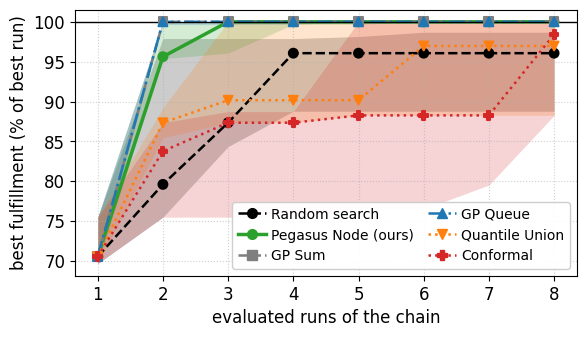

optimizer: gradient steps
legend_inside: the legend hides 2 points or bands at its best location (lower right)


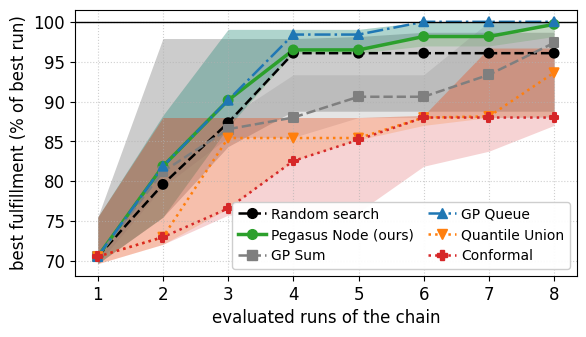

In [6]:
optimization_figure(c2_found, f"C.2 optimizing the configuration, {c2_source} data: {' → '.join(c2_setup['base'].path)}, "
                              f"{arrival_text(c2_bases[seeds[0]].workload)}, {len(seeds)} seeds", name=f"c2_optimization_{c2_source}")

In [7]:
after = lambda optimizer, name, evaluations: np.median(c2_found[optimizer][name][evaluations - 1])   # median over the seeds
found_best = lambda optimizer, name: int(np.sum(np.isclose(c2_found[optimizer][name][-1], 1.0)))       # seeds in which the best existing run was found
display(Markdown(
    f"**What this shows** ({c2_source} data, {arrival_text(c2_bases[seeds[0]].workload)}, ε = {alpha:g}, {len(seeds)} seeds, latency target "
    f"{1e3 * latency_target:.0f} ms).\n"
    f"- **The best existing run** has a true SLO fulfillment of {np.median(c2_best_true):.2f} (median over the seeds; 1 would fulfill every SLO).\n"
    + "".join(
        f"- **Optimizer \"{optimizer}\".** Best true SLO fulfillment found, in percent of the best existing run, after 2 and after {c2_budget} "
        f"evaluated runs (median over the seeds), and the number of seeds in which the best existing run was found: "
        + "; ".join(f"{name} {after(optimizer, name, 2):.0%} and {after(optimizer, name, c2_budget):.0%} ({found_best(optimizer, name)} of {len(seeds)})"
                    for name in c2_names)
        + ".\n" for optimizer in c2_found)
    + "\n**Promises on the latency SLO** (counts over all seeds; the runs that an optimizer chose with a method).\n\n"
    + "| Optimizer | Method | Chosen runs | Violate the latency SLO | Promised to meet it | Promises broken |\n|---|---|---|---|---|---|\n"
    + "\n".join(f"| {optimizer} | {name} | {c['chosen']} | {c['violated']} ({c['violated'] / c['chosen']:.0%}) | {c['promised']} | "
                + (f"{c['broken']} ({c['broken'] / c['promised']:.0%})" if c['promised'] else "none promised") + " |"
                for optimizer in c2_found for name, c in c2_promises[optimizer].items())
))

**What this shows** (synthetic data, poisson arrivals at 4/s, ε = 0.05, 3 seeds, latency target 251 ms).
- **The best existing run** has a true SLO fulfillment of 1.00 (median over the seeds; 1 would fulfill every SLO).
- **Optimizer "best of the runs".** Best true SLO fulfillment found, in percent of the best existing run, after 2 and after 8 evaluated runs (median over the seeds), and the number of seeds in which the best existing run was found: Random search 80% and 96% (0 of 3); Pegasus Node (ours) 96% and 100% (3 of 3); GP Sum 100% and 100% (3 of 3); GP Queue 100% and 100% (3 of 3); Quantile Union 87% and 97% (1 of 3); Conformal 84% and 98% (1 of 3).
- **Optimizer "gradient steps".** Best true SLO fulfillment found, in percent of the best existing run, after 2 and after 8 evaluated runs (median over the seeds), and the number of seeds in which the best existing run was found: Random search 80% and 96% (0 of 3); Pegasus Node (ours) 82% and 100% (1 of 3); GP Sum 81% and 97% (1 of 3); GP Queue 82% and 100% (2 of 3); Quantile Union 73% and 94% (0 of 3); Conformal 73% and 88% (0 of 3).

**Promises on the latency SLO** (counts over all seeds; the runs that an optimizer chose with a method).

| Optimizer | Method | Chosen runs | Violate the latency SLO | Promised to meet it | Promises broken |
|---|---|---|---|---|---|
| best of the runs | Random search | 21 | 11 (52%) | 0 | none promised |
| best of the runs | Pegasus Node (ours) | 21 | 1 (5%) | 4 | 0 (0%) |
| best of the runs | GP Sum | 21 | 7 (33%) | 15 | 3 (20%) |
| best of the runs | GP Queue | 21 | 3 (14%) | 9 | 0 (0%) |
| best of the runs | Quantile Union | 21 | 19 (90%) | 0 | none promised |
| best of the runs | Conformal | 21 | 20 (95%) | 0 | none promised |
| gradient steps | Random search | 21 | 11 (52%) | 0 | none promised |
| gradient steps | Pegasus Node (ours) | 21 | 7 (33%) | 3 | 0 (0%) |
| gradient steps | GP Sum | 21 | 14 (67%) | 11 | 4 (36%) |
| gradient steps | GP Queue | 21 | 9 (43%) | 10 | 0 (0%) |
| gradient steps | Quantile Union | 21 | 21 (100%) | 0 | none promised |
| gradient steps | Conformal | 21 | 21 (100%) | 0 | none promised |